# Hypothesis testing

## ANOVA

**AN**alysis **O**f **VA**riance (ANOVA) is a statistical method to test whether there are significant differences between the means of three or more groups. It has two main types:

1) One-way ANOVA: Tests differences between groups based on one independent variable.

2) Two-way ANOVA: Considers two independent variables.

## ANOVA in R

To learn how to perform ANOVA in R, we will use the data from the paper:

[Chemogenetic attenuation of neuronal activity in the entorhinal cortex reduces Aβ and tau pathology in the hippocampus](https://journals.plos.org/plosbiology/article?id=10.1371/journal.pbio.3000851)

The data is available in the supplementary materials of the paper (link).

Here, we’ll reproduce the results from Figure 3c of the manuscript.

The data for Figure 3 is in the sheet 3 of the Excel file. We’ll skip the first row which just contains some header information. Also we need data from the first six columns (A-F). To read the excel file we’ll use `read_excel` function from the `readxl` package.

After creating a dataframe `LH_gamma`, we will convert the `Genotype` column to a factor since this will be required for the subsequent ANOVA analysis.

In [4]:
#| include: false
install.packages("multcomp")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘zoo’, ‘mvtnorm’, ‘TH.data’, ‘sandwich’




In [12]:
#| warning: false
#| message: false
library(readxl)
library(tidyverse)
library(multcomp)

LH_gamma <- read_excel("plos_bio1.xlsx", sheet=3, range="A2:F39")

LH_gamma_2 <- LH_gamma %>%
  mutate(Genotype = factor(Genotype, levels = c("Control", "EC-Tau", "hAPP", "EC-Tau/hAPP")))
head(LH_gamma)

Mouse ID,Genotype,Sex,Theta (4-12 Hz) %,Low Gamma (35-55 Hz) %,High Gamma (65-120 Hz) %
<chr>,<chr>,<chr>,<dbl>,<dbl>,<chr>
250704a2,Control,Male,59.56905,5.049760,5.4189129999999999
270704a3,Control,Male,34.02242,9.374330,5.4359440000000001
60704a4,Control,Male,47.09975,9.050000,5.8367961529999999
60704a5,Control,Male,30.06438,6.963757,5.8191324069999997
270704-3,Control,Female,39.36074,8.228760,8.3063029999999998
430704-1,Control,Female,64.24069,4.838260,6.6968300000000003


To perform ANOVA, we will use the aov function. For our analysis we want to test the null hypothesis that the means of the four Genotypes are equal. The independent varialbe is Theta (4-12 Hz) % and the dependent variable is Genotype. So, the formula for the ANOVA is: `Theta (4-12 Hz) % ~ Genotype`

Next, we will use the `glht` function from the `multcomp` package to perform post-hoc analysis. `glht` stands for “general linear hypothesis test”. The `glht` function takes the ANOVA results and the type of post-hoc test as arguments. In our case, we will use Dunnett’s test to compare each group with the control group. The `mcp` function is used to specify the type of comparison.

By default the first group is considered as the control group. If you want to change the control group, you can use the `control` argument in the `mcp` function.



In [7]:
anova_results <- aov(`Theta (4-12 Hz) %` ~ Genotype, data=LH_gamma_2)
dunnett_results <- glht(anova_results, linfct = mcp(Genotype = "Dunnett"))
summary_dunnett <- summary(dunnett_results)
summary_dunnett


	 Simultaneous Tests for General Linear Hypotheses

Multiple Comparisons of Means: Dunnett Contrasts


Fit: aov(formula = `Theta (4-12 Hz) %` ~ Genotype, data = LH_gamma_2)

Linear Hypotheses:
                           Estimate Std. Error t value Pr(>|t|)   
EC-Tau - Control == 0        -7.128      6.176  -1.154  0.52347   
hAPP - Control == 0         -15.961      5.840  -2.733  0.02675 * 
EC-Tau/hAPP - Control == 0  -19.185      5.840  -3.285  0.00652 **
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1
(Adjusted p values reported -- single-step method)


### Preparing the data for plotting

Based on the p-values for the pairwise comparison, a stars variable is created to hold the significance level of each comparison. The cut function is used to create a categorical variable based on the p-values stored in the `p_values` variable. The `breaks` argument specifies the cut points for the categories, and the `labels` argument specifies the labels for each category.

The names for the pair of groups being compared are stored in the `pair_names` variable. These names can be accessed using the `names` function on the `summary_dunnett$test$tstat` object.

The `LH_gamma_summary` dataframe is created using the `group_by` and `summarise` functions from the `dplyr` package. The `mean_theta` and `sem_theta` (standard error of the mean) are calculated for each Genotype group.


In [17]:
# 1. Capture the printed console text of the summary
summary_lines <- capture.output(summary(summary_dunnett))

# 2. Filter only the lines that contain the linear hypotheses (identified by '== 0')
hypothesis_lines <- grep("== 0", summary_lines, value = TRUE)

# 3. Extract the final token of each line (either the significance star or the p-value)
extracted_symbols <- sapply(hypothesis_lines, function(line) {
  tokens <- strsplit(trimws(line), "\\s+")[[1]]
  last_token <- tail(tokens, 1)

  # If the last token is a number, there is no star -> map it to "ns"
  if (grepl("^[0-9.]+$", last_token)) {
    return("ns")
  } else {
    return(last_token) # Returns "*", "**", or "***"
  }
})

# Clean up the vector names
names(extracted_symbols) <- NULL

# View the result
print(extracted_symbols)

[1] "ns" "*"  "**"


In [15]:
p_values <- summary_dunnett$test$pvalues
stars <- cut(p_values,
             breaks = c(-Inf, 0.001, 0.01, 0.05, 1),
             labels = c("***", "**", "*", "ns"))

LH_gamma_summary <- LH_gamma %>%
  group_by(Genotype) %>%
  summarize(
    mean_theta = mean(`Theta (4-12 Hz) %`, na.rm = TRUE),
    sem_theta = sd(`Theta (4-12 Hz) %`, na.rm = TRUE) / sqrt(n())
  )
LH_gamma_summary

Genotype,mean_theta,sem_theta
<chr>,<dbl>,<dbl>
Control,42.40957,5.480056
EC-Tau,35.28125,5.472521
EC-Tau/hAPP,23.22467,3.082346
hAPP,26.44856,2.658695


### Plotting

To re-create the Figure 3c from the paper, we’ll use ggplot2 to create multiple geometric layers. The first layer is a bar plot with error bars. The `geom_bar` function is used to create the bars, and the `geom_errorbar` function is used to add error bars. The `geom_jitter` function is used to add individual data points to the plot. The `geom_text` function is used to add the mean values on the bars.

To show the statistical significance, we will use the `geom_text` function to add asterisks to the plot. The `geom_segment` function is used to draw lines between the groups being compared.

Finally, the plot is customized using the theme function to adjust the appearance of the plot. The `scale_fill_manual` function is used to set the colors for each Genotype group.

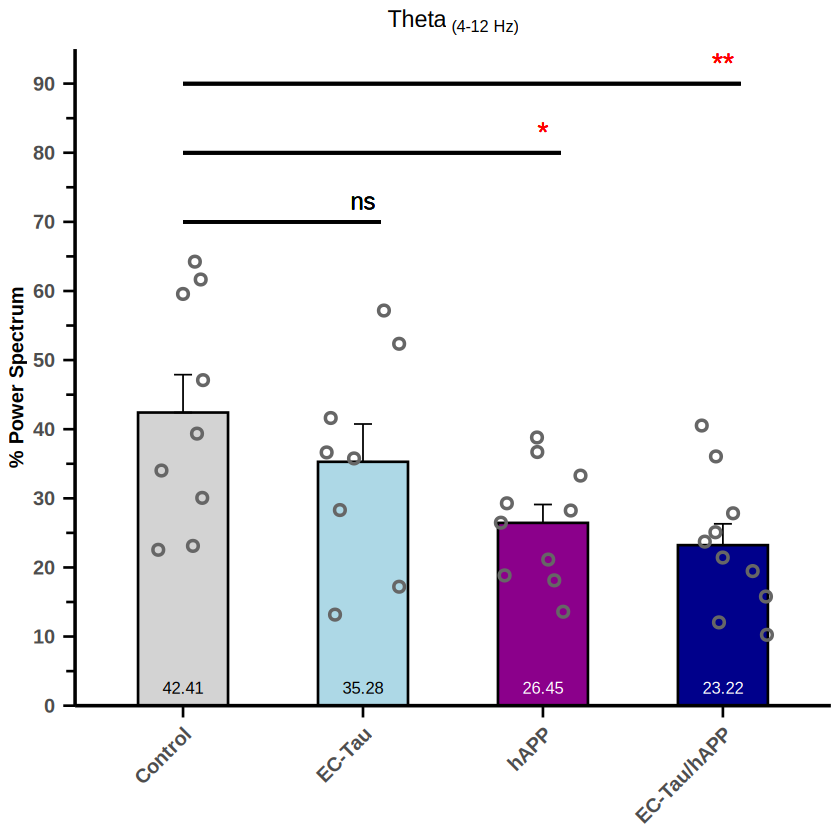

In [9]:
ggplot(LH_gamma_summary, aes(x = reorder(Genotype, mean_theta, FUN = mean, decreasing = TRUE),
                             y = mean_theta, fill = Genotype)) +
  geom_bar(stat = "identity", color = "black", width = 0.5, linewidth = 0.75, position = "dodge") +
  geom_errorbar(aes(ymin = mean_theta, ymax = mean_theta + sem_theta), width = 0.1) +
  geom_jitter(data = LH_gamma, aes(x = Genotype, y = `Theta (4-12 Hz) %`),
              width = 0.25, height = 0, size = 2, shape = 1, stroke=1.5, color="#666666") +
  # show means on bars
  geom_text(aes(label = round(mean_theta, 2), y = 0), size = 3.5, vjust = -1,
            color = rep(c("black", "white"), each = 2)) +
  geom_text(aes(x=2,y=73,label = stars[1]), size = 5, color="black") +
  geom_segment(aes(x=1, xend=2.10, y=70, yend=70), color="black", linewidth =1) +
  geom_text(aes(x=3,y=83,label = stars[2]), size = 6, color="red") +
  geom_segment(aes(x=1, xend=3.10, y=80, yend=80), color="black", linewidth=1) +
  geom_text(aes(x=4,y=93,label = stars[3]), size = 6, color="red") +
  geom_segment(aes(x=1, xend=4.10, y=90, yend=90), color="black", linewidth=1) +
  scale_fill_manual(values = c("Control" = "lightgrey", "EC-Tau" = "lightblue", "hAPP"="darkmagenta", "EC-Tau/hAPP" = "darkblue")) +
  scale_y_continuous(breaks = seq(0, 90, by = 10), limits = c(0, 95),
                     expand = c(0,0),
                     minor_breaks = seq(0, 90, by = 5)) +
  theme_minimal() +
  guides(y=guide_axis(minor.ticks = TRUE)) +
  ylab("% Power Spectrum") +
  ggtitle(expression("Theta" [" (4-12 Hz)"])) +
  theme(axis.title.x = element_blank(),
        axis.title.y = element_text(size = 12, face = "bold"),
        axis.text.x = element_text(angle = 45, hjust = 1),
        axis.text = element_text(size = 12, face = "bold"),
        axis.ticks = element_line(linewidth = 0.75),
        axis.ticks.length = unit(0.25, "cm"),
        axis.line = element_line(linewidth = 1),
        panel.grid.major = element_blank(),
        panel.grid.minor = element_blank(),
        legend.position = "none",
        plot.title = element_text(hjust=0.5, size = 14, face = "bold"))
#ggsave("LH_gamma.png", width=4, height=5, dpi=300, bg="white")